# NumPy-Only Neural Network Demo
This notebook demonstrates training a simple neural network built from scratch using only NumPy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from nn.activations import ActivationFunction
from nn.network import NeuralNetwork
from data.mnist import load_mnist


## Load MNIST subset

In [2]:
X, y, y_onehot = load_mnist(n_samples=12000)
print('Features shape:', X.shape)
print('Labels shape:', y.shape)

Features shape: (12000, 784)
Labels shape: (12000,)


## Initialize and train the network

In [3]:
input_size = 28*28
hidden_size = 64
output_size = 10

nn_model = NeuralNetwork(
    layer_sizes=[input_size, hidden_size, output_size],
    hidden_activation=ActivationFunction.relu,
    output_activation=ActivationFunction.softmax
)

epochs = 20
learning_rate = 5e-3

losses = nn_model.train(X, y_onehot, epochs=epochs, lr=learning_rate)

Epoch 0: loss=0.4369
Epoch 1: loss=0.2373
Epoch 2: loss=0.1796
Epoch 3: loss=0.1423
Epoch 4: loss=0.1157
Epoch 5: loss=0.0950
Epoch 6: loss=0.0782
Epoch 7: loss=0.0649
Epoch 8: loss=0.0543
Epoch 9: loss=0.0456
Epoch 10: loss=0.0386
Epoch 11: loss=0.0326
Epoch 12: loss=0.0275
Epoch 13: loss=0.0235
Epoch 14: loss=0.0201
Epoch 15: loss=0.0171
Epoch 16: loss=0.0149
Epoch 17: loss=0.0128
Epoch 18: loss=0.0112
Epoch 19: loss=0.0099


## Plot training loss

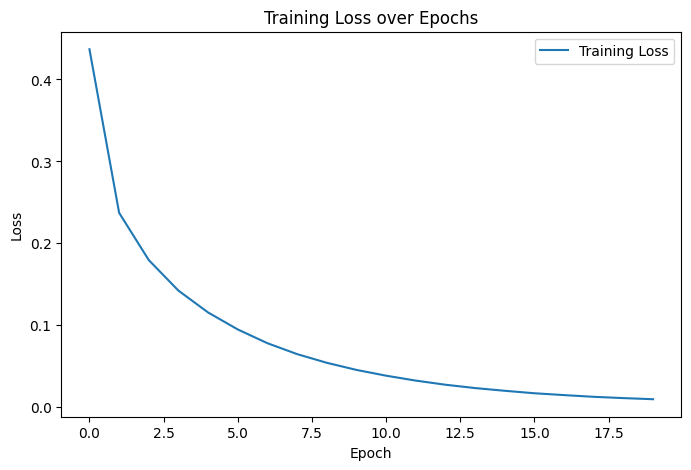

In [4]:
plt.figure(figsize=(8,5))
plt.plot(losses, label='Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss over Epochs')
plt.legend()
plt.show()

## Evaluate accuracy

In [5]:
preds = nn_model.predict(X)
pred_labels = np.argmax(preds, axis=1)
accuracy = np.mean(pred_labels == y)
print(f'Train accuracy: {accuracy*100:.2f}%')

Train accuracy: 99.83%


## Show sample predictions

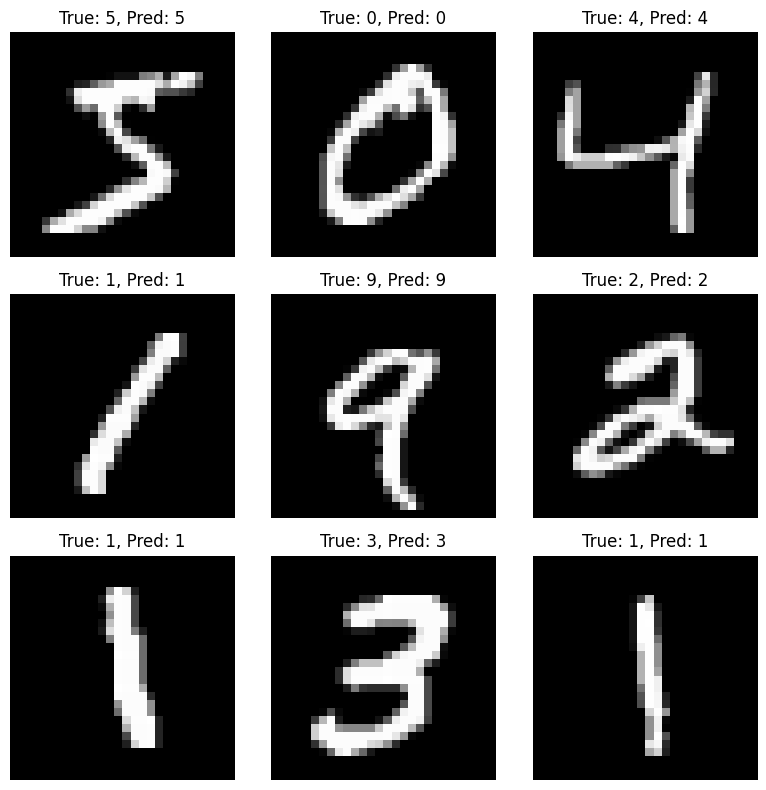

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(8,8))
for i, ax in enumerate(axes.flatten()):
    img = X[i].reshape(28,28)
    ax.imshow(img, cmap='gray')
    ax.set_title(f'True: {y[i]}, Pred: {pred_labels[i]}')
    ax.axis('off')
plt.tight_layout()
plt.show()